In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "font.family": "serif",
    "figure.dpi": 300,
})
import glob
import os

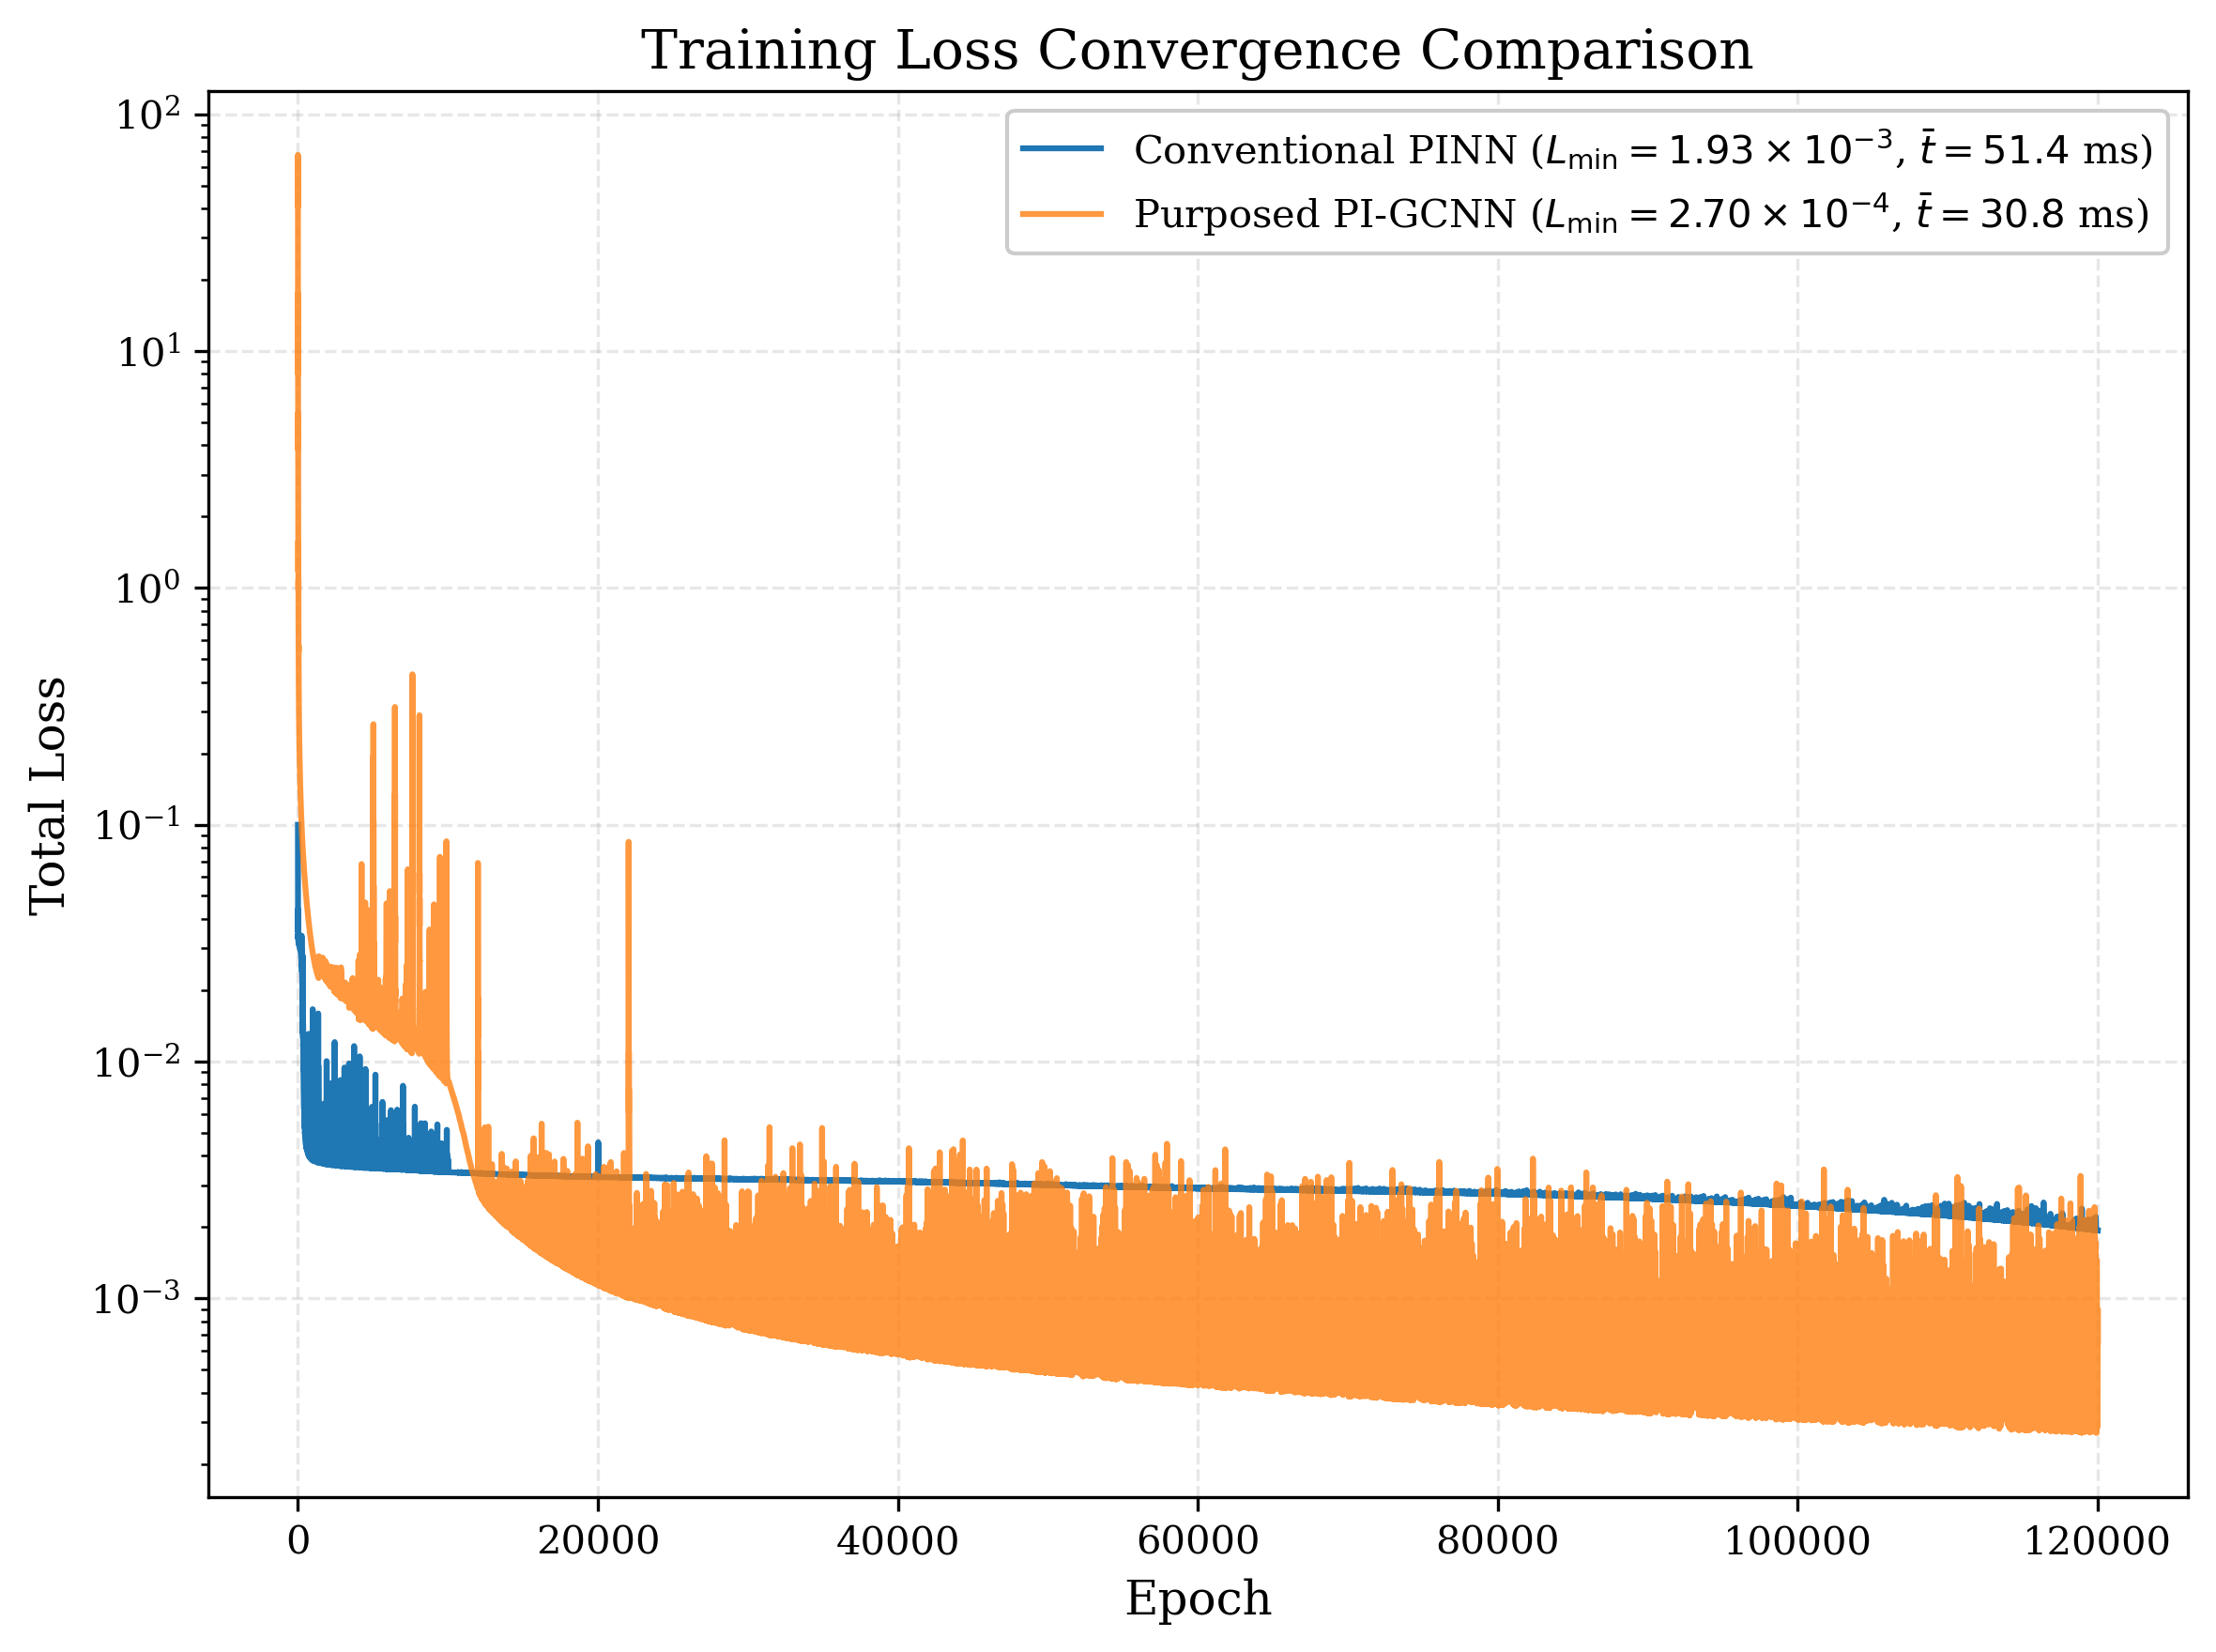

In [9]:
def sci_notation(x):
    if x == 0:
        return "0"
    exp = int(np.floor(np.log10(abs(x))))
    coef = x / 10**exp
    return f"{coef:.2f} \\times 10^{{{exp}}}"

def load_and_merge(folder_path):
    csv_files = sorted(glob.glob(f"{folder_path}/loss_history_run*.csv"))
    dfs = []
    epoch_offset = 0
    for file in csv_files:
        df = pd.read_csv(file)
        df['epoch'] = df['epoch'] + epoch_offset
        epoch_offset = df['epoch'].max() + 1
        dfs.append(df)
    return pd.concat(dfs, ignore_index=True)

def load_time_data(folder_path):
    csv_files = sorted(glob.glob(f"{folder_path}/adam_epoch_time_run*.csv"))
    if not csv_files:
        return 30.8
    
    dfs = []
    for file in csv_files:
        df = pd.read_csv(file)
        dfs.append(df)
    combined = pd.concat(dfs, ignore_index=True)

    time_col = 'time' if 'time' in combined.columns else 'duration'
    avg_time_ms = combined[time_col].mean() * 1000 
    return avg_time_ms


folder1 = "i-PINNs-forward-Results/history"
folder2 = "iii-GPINNs-forward-Results/history"

df1 = load_and_merge(folder1)
df2 = load_and_merge(folder2)

avg_time1 = load_time_data(folder1)
avg_time2 = load_time_data(folder2)

min_common_epoch = min(df1['epoch'].max(), df2['epoch'].max())
df1_trim = df1[df1['epoch'] <= min_common_epoch]
df2_trim = df2[df2['epoch'] <= min_common_epoch]

min1 = df1_trim['loss_total'].min()
min2 = df2_trim['loss_total'].min()
min1_tex = sci_notation(min1)
min2_tex = sci_notation(min2)

label1 = f'Conventional PINN ($L_{{\\mathrm{{min}}}}={min1_tex}$'
if avg_time1 is not None:
    label1 += f', $\\bar{{t}}={avg_time1:.1f}$ ms'
label1 += ')'

label2 = f'Purposed PI-GCNN ($L_{{\\mathrm{{min}}}}={min2_tex}$'
if avg_time2 is not None:
    label2 += f', $\\bar{{t}}={avg_time2:.1f}$ ms'
label2 += ')'

plt.figure(figsize=(8, 6))
plt.plot(df1_trim['epoch'], df1_trim['loss_total'], label=label1, linewidth=1.5, alpha=1.0)
plt.plot(df2_trim['epoch'], df2_trim['loss_total'], label=label2, linewidth=1.5, alpha=0.8)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Total Loss", fontsize=12)
plt.title("Training Loss Convergence Comparison", fontsize=14)
plt.yscale("log")
plt.grid(alpha=0.3, linestyle='--')
plt.legend(fontsize=10, framealpha=1.0)
plt.tight_layout()
plt.savefig("Input/loss_comparison.png", dpi=300, bbox_inches='tight')
plt.show()